# Figure 1 of Zhang et al. (2017), *Understanding deep learning requires rethinking generalization*

This notebook redraws the figure and prints the numbers in the report from the saved logs in `results/`.
Set `RUN_TRAINING = True` to retrain everything with `run_all.sh` first (about 3.5 h on an Apple M4 Pro).

In [1]:
import json, os, subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run(["bash", "run_all.sh"], check=True)

## Parameter counts against Table 1 of the paper

In [2]:
!python3 models.py

inception   1,649,402   paper  1,649,402   ok
alexnet     1,387,786   paper  1,387,786   ok
mlp1        1,209,866   paper  1,209,866   ok
mlp3        1,735,178   paper  1,735,178   ok


## Randomization tests
With corruption probability $p$ a label is replaced by a uniform draw from the 10 classes, so only $0.9p$ of the labels change. This cell needs CIFAR-10 (set `CIFAR10_NPZ` or let torchvision download it).

first image after whitening: mean 0.000, std 1.000
p=0.2: labels changed 0.179   (0.9p = 0.180)
p=0.4: labels changed 0.357   (0.9p = 0.360)
p=0.6: labels changed 0.540   (0.9p = 0.540)
p=0.8: labels changed 0.720   (0.9p = 0.720)
p=1.0: labels changed 0.899   (0.9p = 0.900)


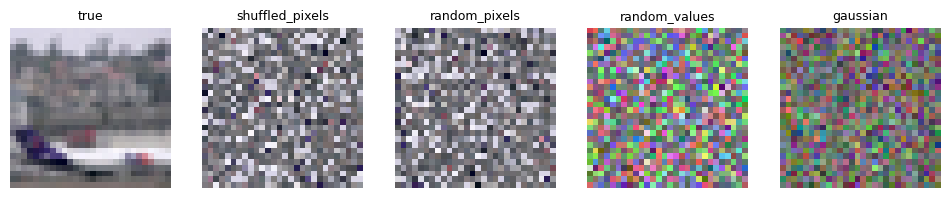

In [3]:
import torch
from data import load_cifar10, preprocess, randomize

x_train, y_train, x_test, y_test = load_cifar10(os.environ.get("CIFAR10_NPZ"))
x_train, x_test = preprocess(x_train), preprocess(x_test[:500])
y_train, y_test = torch.from_numpy(y_train).long(), torch.from_numpy(y_test[:500]).long()
print(f"first image after whitening: mean {x_train[0].mean():.3f}, std {x_train[0].std():.3f}")

for p in [0.2, 0.4, 0.6, 0.8, 1.0]:
    y_noisy = randomize(x_train, y_train, x_test, y_test, "corrupt", p)[1]
    print(f"p={p}: labels changed {(y_noisy != y_train).float().mean():.3f}   (0.9p = {0.9 * p:.3f})")

modes = ["true", "shuffled_pixels", "random_pixels", "random_values", "gaussian"]
fig, axes = plt.subplots(1, len(modes), figsize=(12, 2.6))
for ax, mode in zip(axes, modes):
    img = randomize(x_train[:64], y_train[:64], x_test, y_test, mode)[0][0].permute(1, 2, 0).numpy()
    ax.imshow((img - img.min()) / (img.max() - img.min()))
    ax.set_title(mode, fontsize=9)
    ax.axis("off")
plt.show()

## Figure 1
Convergence time is the number of SGD steps until the accuracy on the whole training set first reaches 99%. "Random pixels" permutes all 2352 values of an image; the dashed curve keeps the three color values of a pixel together. Panel (c) uses the real test labels, panel (c') test labels corrupted with the same $p$ as the training labels.

inception
  p=0.0  steps=  5460  ratio=1.00  test err=0.131  corrupted labels: formula=0.131 measured=  n/a
  p=0.2  steps=  8580  ratio=1.57  test err=0.274  corrupted labels: formula=0.399 measured=  n/a
  p=0.4  steps= 10920  ratio=2.00  test err=0.436  corrupted labels: formula=0.622 measured=  n/a
  p=0.6  steps= 12480  ratio=2.29  test err=0.625  corrupted labels: formula=0.790 measured=  n/a
  p=0.8  steps= 14820  ratio=2.71  test err=0.784  corrupted labels: formula=0.877 measured=  n/a
  p=1.0  steps= 19500  ratio=3.57  test err=0.895  corrupted labels: formula=0.900 measured=  n/a
alexnet
  p=0.0  steps=  5070  ratio=1.00  test err=0.222  corrupted labels: formula=0.222 measured=  n/a
  p=0.2  steps=  7800  ratio=1.54  test err=0.358  corrupted labels: formula=0.466 measured=  n/a
  p=0.4  steps=  9360  ratio=1.85  test err=0.484  corrupted labels: formula=0.650 measured=0.654
  p=0.6  steps= 10530  ratio=2.08  test err=0.639  corrupted labels: formula=0.795 measured=0.798
  

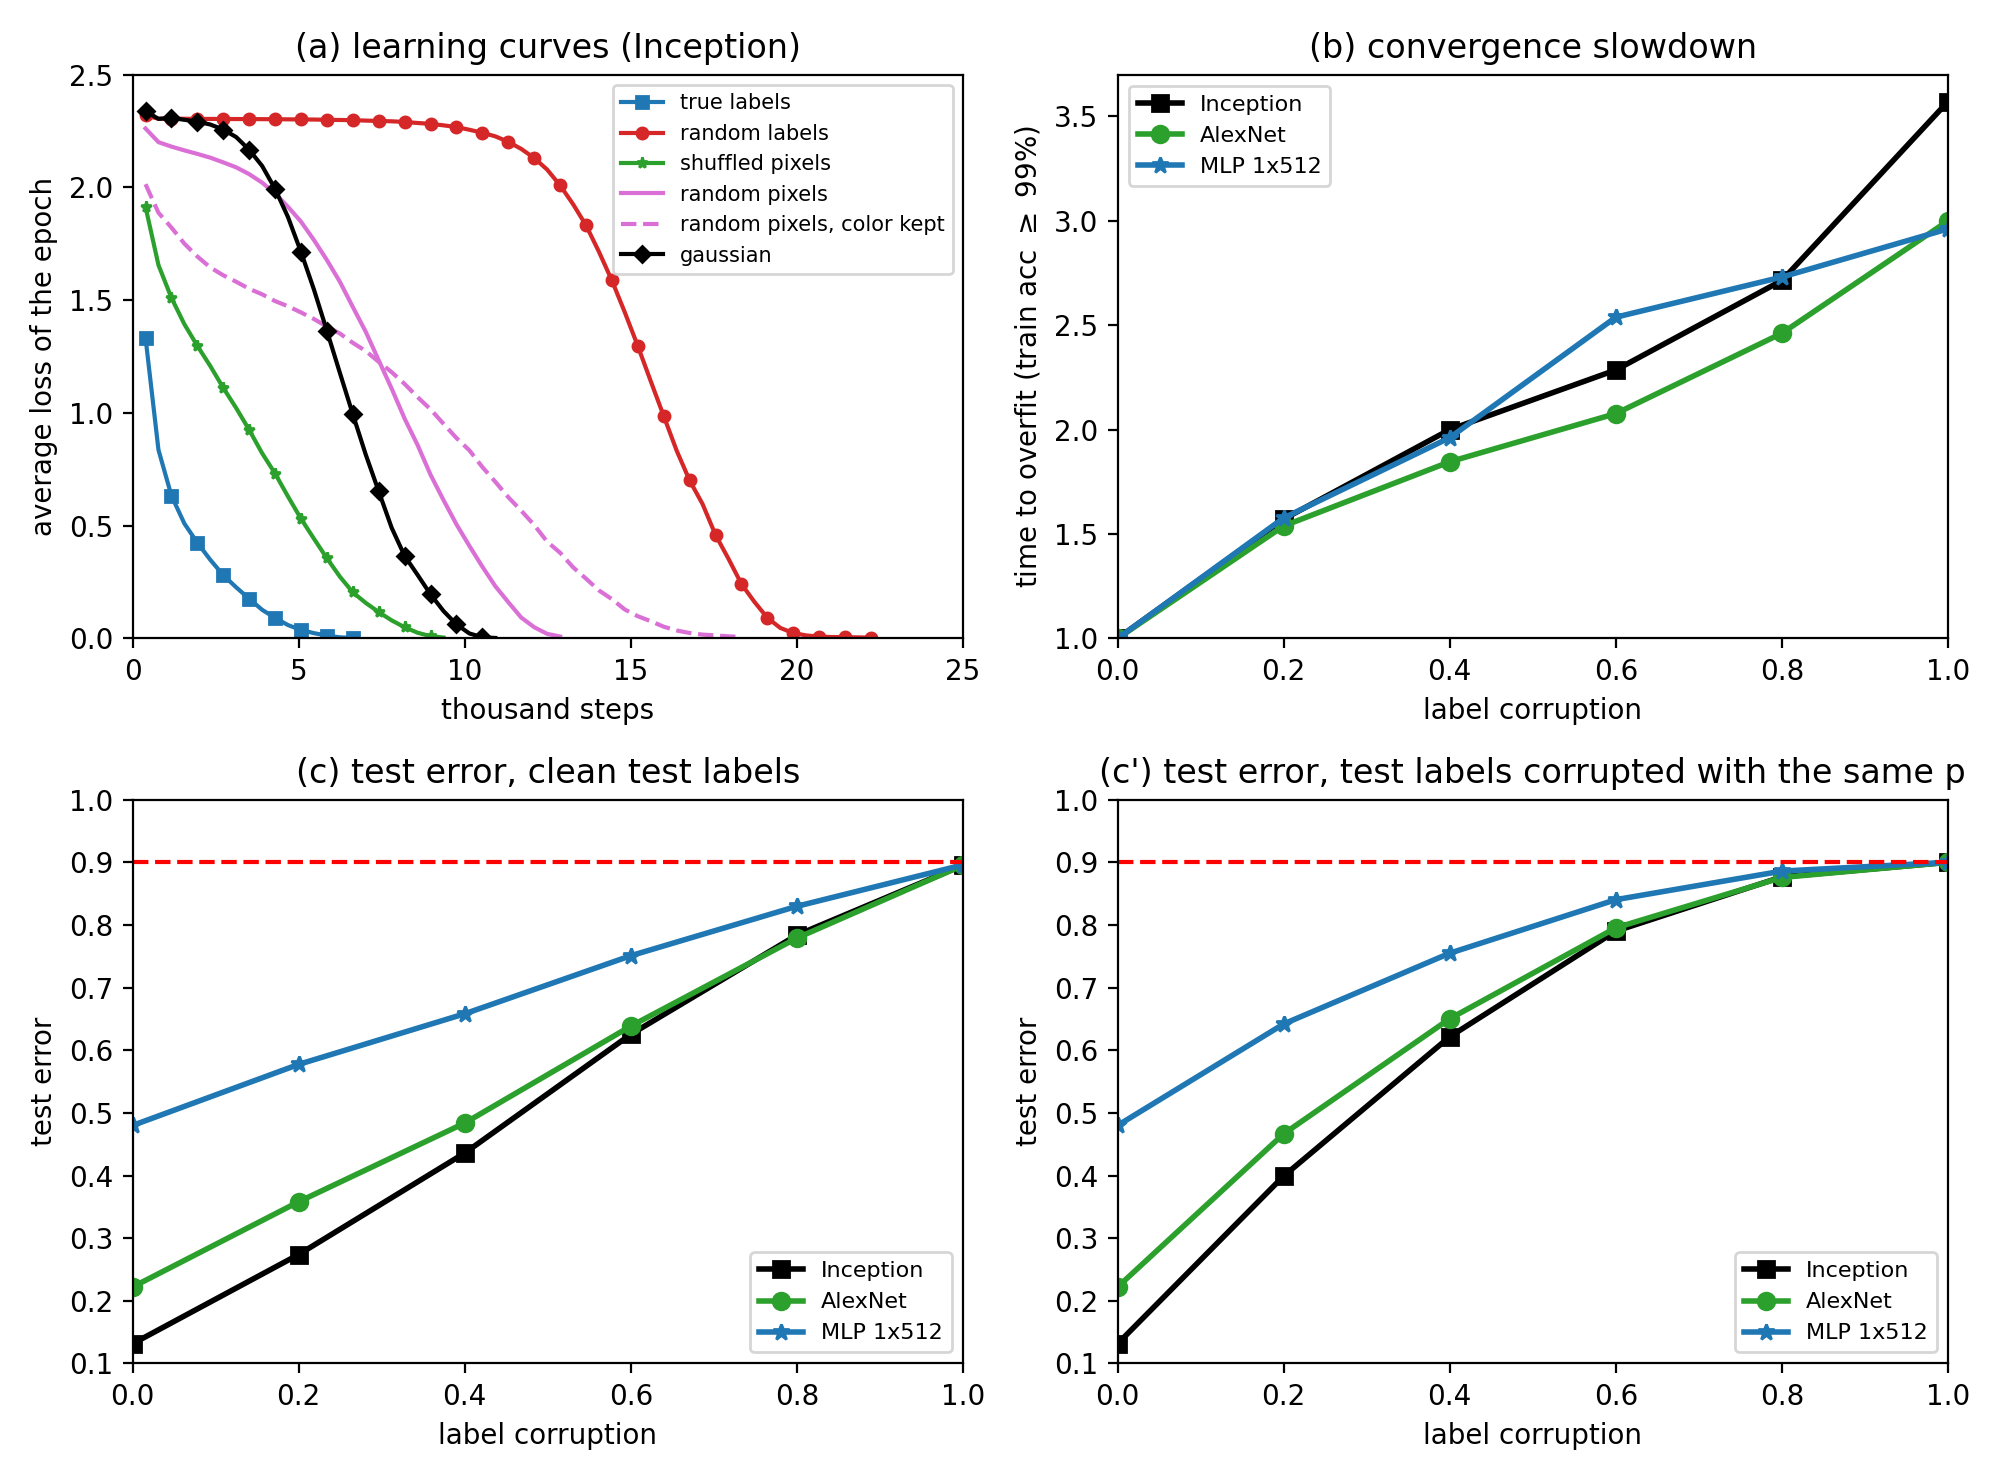

In [4]:
!python3 plot_fig1.py
display(Image("figures/fig1_reproduced.png"))

## The paper against my runs
The paper's values were read from the vector graphics of its PDF by `extract_paper_fig1.py`. The last two tables are the diagnostics in the report: the learning curves of panel (a), and the runs with TensorFlow's default initialization.

In [5]:
!python3 compare_with_paper.py

Panels (b) and (c): time to overfit relative to p=0, test error
network       p |  paper   mine |  paper  clean  corrupted (formula / measured)
inception   0.0 |   1.00   1.00 |  0.129  0.131                0.131 / n/a
inception   0.2 |   1.90   1.57 |  0.406  0.274                0.399 / n/a
inception   0.4 |   2.40   2.00 |  0.629  0.436                0.622 / n/a
inception   0.6 |   2.70   2.29 |  0.785  0.625                0.790 / n/a
inception   0.8 |   3.10   2.71 |  0.879  0.784                0.877 / n/a
inception   1.0 |   3.60   3.57 |  0.902  0.895                0.900 / n/a
alexnet     0.0 |   1.00   1.00 |  0.301  0.222                0.222 / n/a
alexnet     0.2 |   1.10   1.54 |  0.522  0.358                0.466 / n/a
alexnet     0.4 |   1.23   1.85 |  0.692  0.484                0.650 / 0.654
alexnet     0.6 |   1.32   2.08 |  0.820  0.639                0.795 / 0.798
alexnet     0.8 |   1.42   2.46 |  0.881  0.779                0.876 / 0.871
alexnet     1.0 |   1.55 

## Every run

In [6]:
from plot_fig1 import load_all, steps_to

print(f"{'run':30s} {'changed':>7s} {'epochs':>6s} {'train acc':>9s} {'test err':>8s} {'best test err':>15s}"
      "   steps to 95 / 99 / 100% train acc")
for tag, run in sorted(load_all("results").items()):
    test_acc = np.array(run["test_acc"])
    changed = run.get("frac_labels_changed")
    changed = "" if changed is None else f"{changed:.3f}"
    best = f"{1 - test_acc.max():.3f} (ep {test_acc.argmax() + 1})"
    steps = " / ".join(str(steps_to(run, t)) for t in (0.95, 0.99, 1.0))
    print(f"{tag:30s} {changed:>7s} {run['epoch'][-1]:6d} {run['train_acc'][-1]:9.4f} "
          f"{1 - test_acc[-1]:8.3f} {best:>15s}   {steps}")

run                            changed epochs train acc test err   best test err   steps to 95 / 99 / 100% train acc
alexnet_corrupt_p0.20_s0         0.179     39    1.0000    0.358    0.290 (ep 9)   6630 / 7800 / 15210
alexnet_corrupt_p0.40_s0         0.357     47    1.0000    0.484    0.323 (ep 9)   8190 / 9360 / 18330
alexnet_corrupt_p0.60_s0         0.540     53    1.0000    0.639    0.381 (ep 9)   9360 / 10530 / 20670
alexnet_corrupt_p0.80_s0         0.720     57    1.0000    0.779    0.522 (ep 7)   11310 / 12480 / 22230
alexnet_corrupt_p1.00_s0         0.899     81    1.0000    0.895    0.882 (ep 4)   14040 / 15210 / 31590
alexnet_true_s0                            16    1.0000    0.222   0.222 (ep 16)   3900 / 5070 / 6240
inception_corrupt_p0.20_s0       0.179     26    1.0000    0.274    0.225 (ep 8)   8580 / 8580 / 10140
inception_corrupt_p0.40_s0       0.357     30    1.0000    0.436    0.261 (ep 8)   10140 / 10920 / 11700
inception_corrupt_p0.60_s0       0.540     36    1.00

## Panel (b) for other convergence thresholds
Time to overfit relative to $p=0$, for $p = 0, 0.2, \dots, 1$, and the epochs needed at $p=0$ and $p=1$.

In [7]:
with open("figures/fig1_reproduced_summary.json") as f:
    summary = json.load(f)

for arch, rows in summary.items():
    for th in ("0.95", "0.99", "0.999", "1.0"):
        steps = [r["steps_by_threshold"][th] for r in rows]
        ratios = ["  n/a" if s is None or steps[0] is None else f"{s / steps[0]:5.2f}" for s in steps]
        epochs = [None if s is None else s // 390 for s in (steps[0], steps[-1])]
        print(f"{arch:9s} {th:>5s}: {' '.join(ratios)}   epochs at p=0: {epochs[0]}, at p=1: {epochs[1]}")

inception  0.95:  1.00  2.00  2.36  2.82  3.36  4.45   epochs at p=0: 11, at p=1: 49
inception  0.99:  1.00  1.57  2.00  2.29  2.71  3.57   epochs at p=0: 14, at p=1: 50
inception 0.999:  1.00  1.60  1.87  2.27  2.60  3.40   epochs at p=0: 15, at p=1: 51
inception   1.0:  1.00  1.53  1.76  2.12  2.53  3.35   epochs at p=0: 17, at p=1: 57
alexnet    0.95:  1.00  1.70  2.10  2.40  2.90  3.60   epochs at p=0: 10, at p=1: 36
alexnet    0.99:  1.00  1.54  1.85  2.08  2.46  3.00   epochs at p=0: 13, at p=1: 39
alexnet   0.999:  1.00  1.60  1.87  2.07  2.47  3.00   epochs at p=0: 15, at p=1: 45
alexnet     1.0:  1.00  2.44  2.94  3.31  3.56  5.06   epochs at p=0: 16, at p=1: 81
mlp1       0.95:  1.00  1.50  1.70  1.90  2.05  2.15   epochs at p=0: 20, at p=1: 43
mlp1       0.99:  1.00  1.58  1.96  2.54  2.73  2.96   epochs at p=0: 26, at p=1: 77
mlp1      0.999:  1.00   n/a   n/a   n/a   n/a   n/a   epochs at p=0: 41, at p=1: None
mlp1        1.0:   n/a   n/a   n/a   n/a   n/a   n/a   epochs a